<a href="https://colab.research.google.com/github/dikshalande98/EDA/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv(
    "/content/housing.csv"
)

# Create a backup of the original data
original_df = df.copy()

# Display the first five rows
print("First five rows:")
display(df.head())

# Display the last five rows
print("Last five rows:")
display(df.tail())

# Display dataset shape
print("Dataset shape:", df.shape)

# Display column names
print("Column names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)


First five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Last five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


Dataset shape: (20640, 10)
Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object


In [2]:
# Numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

# Categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

# Summary statistics
print("\nNumerical Summary:")
display(df.describe())

# Categorical summary
print("\nCategorical Summary:")
display(df[categorical_columns].describe())

# Unique values in categorical columns
for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())

Numerical columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

Categorical columns:
['ocean_proximity']

Numerical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Categorical Summary:


,ocean_proximity
count,20640
unique,5
top,<1H OCEAN
freq,9136



Unique values in ocean_proximity:
['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']


In [3]:
# Count missing values in each column
missing_counts = df.isnull().sum()

# Calculate missing-value percentages
missing_percentages = (
    df.isnull().sum() / len(df) * 100
).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage": missing_percentages
})

display(missing_summary)

,Missing Values,Missing Percentage
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,207,1.0
population,0,0.0
households,0,0.0
median_income,0,0.0
median_house_value,0,0.0
ocean_proximity,0,0.0


In [4]:
# Create a working copy
df_clean = df.copy()

# Fill missing numerical values using the median
median_bedrooms = df_clean["total_bedrooms"].median()

df_clean["total_bedrooms"] = (
    df_clean["total_bedrooms"].fillna(median_bedrooms)
)

print("Median used:", median_bedrooms)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Median used: 435.0

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [5]:
# Count duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check unique category labels
print("\nCategories before standardisation:")
print(df_clean["ocean_proximity"].unique())

# Remove extra spaces from category labels
df_clean["ocean_proximity"] = (
    df_clean["ocean_proximity"].str.strip()
)

# Check categories again
print("\nCategories after standardisation:")
print(df_clean["ocean_proximity"].unique())

# Check dataset shape
print("\nDataset shape:", df_clean.shape)

Duplicate rows: 0

Categories before standardisation:
['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']

Categories after standardisation:
['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']

Dataset shape: (20640, 10)


In [6]:
display(df_clean.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
print("Ocean proximity frequency:")
display(df_clean["ocean_proximity"].value_counts())

Ocean proximity frequency:


,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


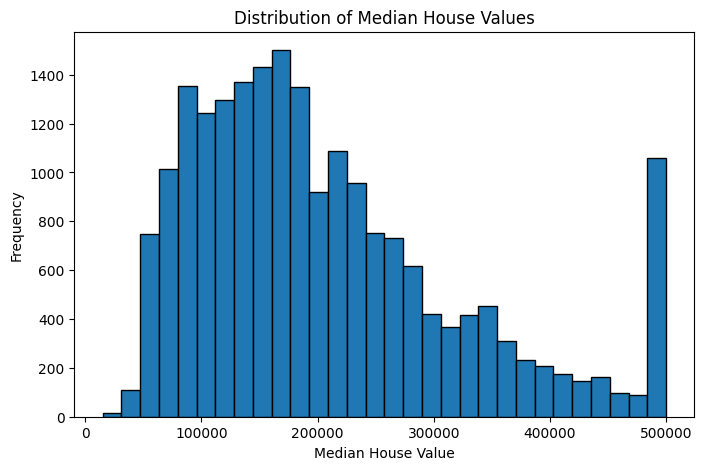

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["median_house_value"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

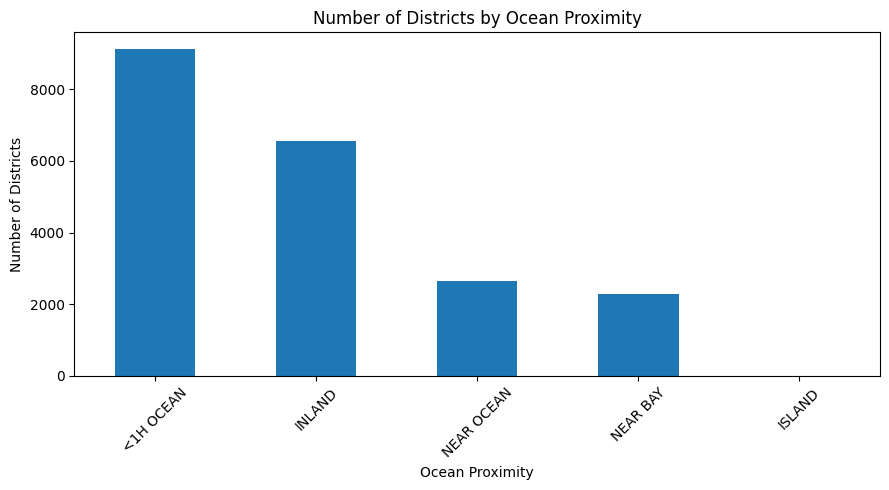

In [9]:
plt.figure(figsize=(9, 5))

df_clean["ocean_proximity"].value_counts().plot(
    kind="bar"
)

plt.title("Number of Districts by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Districts")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

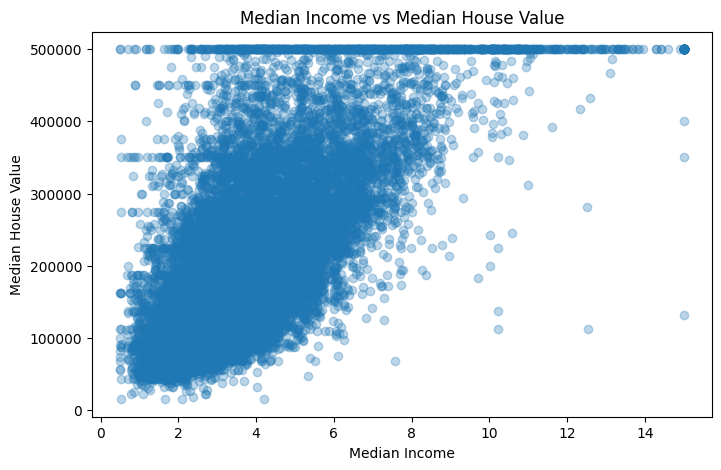

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["median_income"],
    df_clean["median_house_value"],
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [11]:
# One-hot encode the categorical column
df_encoded = pd.get_dummies(
    df_clean,
    columns=["ocean_proximity"],
    dtype=int
)

print("Columns after encoding:")
print(df_encoded.columns.tolist())

display(df_encoded.head())

Columns after encoding:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


In [12]:
from sklearn.preprocessing import StandardScaler

# Select numerical input features to scale
scale_columns = [
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

# Create the scaler
scaler = StandardScaler()

# Apply standardisation
df_encoded[scale_columns] = scaler.fit_transform(
    df_encoded[scale_columns]
)

print("Scaled numerical features:")
display(df_encoded[scale_columns].head())

print("\nMean after scaling:")
print(df_encoded[scale_columns].mean().round(2))

print("\nStandard deviation after scaling:")
print(df_encoded[scale_columns].std().round(2))

Scaled numerical features:


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,0.982143,-0.804819,-0.972476,-0.974429,-0.977033,2.344766
1,-0.607019,2.045890,1.357143,0.861439,1.669961,2.332238
2,1.856182,-0.535746,-0.827024,-0.820777,-0.843637,1.782699
3,1.856182,-0.624215,-0.719723,-0.766028,-0.733781,0.932968
4,1.856182,-0.462404,-0.612423,-0.759847,-0.629157,-0.012881



Mean after scaling:
housing_median_age    0.0
total_rooms           0.0
total_bedrooms       -0.0
population           -0.0
households            0.0
median_income         0.0
dtype: float64

Standard deviation after scaling:
housing_median_age    1.0
total_rooms           1.0
total_bedrooms        1.0
population            1.0
households            1.0
median_income         1.0
dtype: float64


In [13]:
# Check the final shape
print("Final dataset shape:", df_encoded.shape)

# Check remaining missing values
print(
    "Total missing values:",
    df_encoded.isnull().sum().sum()
)

# Check duplicate rows
print(
    "Duplicate rows:",
    df_encoded.duplicated().sum()
)

# Save the prepared dataset
df_encoded.to_csv(
    "california_housing_prepared.csv",
    index=False
)

print("\nDataset saved successfully!")

# Display the prepared dataset
display(df_encoded.head())

Final dataset shape: (20640, 14)
Total missing values: 0
Duplicate rows: 0

Dataset saved successfully!


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,0.982143,-0.804819,-0.972476,-0.974429,-0.977033,2.344766,452600.0,0,0,0,1,0
1,-122.22,37.86,-0.607019,2.045890,1.357143,0.861439,1.669961,2.332238,358500.0,0,0,0,1,0
2,-122.24,37.85,1.856182,-0.535746,-0.827024,-0.820777,-0.843637,1.782699,352100.0,0,0,0,1,0
3,-122.25,37.85,1.856182,-0.624215,-0.719723,-0.766028,-0.733781,0.932968,341300.0,0,0,0,1,0
4,-122.25,37.85,1.856182,-0.462404,-0.612423,-0.759847,-0.629157,-0.012881,342200.0,0,0,0,1,0


In [14]:
from google.colab import files

files.download("california_housing_prepared.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>